In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Load the Diabetes dataset
diabetes = load_diabetes(as_frame=True)

# Store the input features and target
X = diabetes.data
y = diabetes.target

# Display the dataset information
print("Dataset loaded successfully!")
print("Number of rows:", X.shape[0])
print("Number of input features:", X.shape[1])

print("\nFeature names:")
print(X.columns.tolist())

print("\nFirst 5 rows of the dataset:")
display(X.head())


Dataset loaded successfully!
Number of rows: 442
Number of input features: 10

Feature names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

First 5 rows of the dataset:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [3]:

# Check for missing values
print("Missing values in each feature:")
print(X.isnull().sum())

print("\nTarget variable information:")
print(y.describe())

print("\nFeature statistics:")
display(X.describe())


Missing values in each feature:
age    0
sex    0
bmi    0
bp     0
s1     0
s2     0
s3     0
s4     0
s5     0
s6     0
dtype: int64

Target variable information:
count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: target, dtype: float64

Feature statistics:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01


In [4]:

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 353
Testing samples: 89


In [5]:

# Select BMI as the only input feature
X_simple = X[["bmi"]]

print("BMI feature selected successfully!")
display(X_simple.head())


BMI feature selected successfully!


,bmi
0,0.061696
1,-0.051474
2,0.044451
3,-0.011595
4,-0.036385


In [6]:

X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(
    X_simple,
    y,
    test_size=0.2,
    random_state=42
)

print("BMI training samples:", len(X_train_simple))
print("BMI testing samples:", len(X_test_simple))


BMI training samples: 353
BMI testing samples: 89


In [7]:

# Create the model
simple_model = LinearRegression()

# Train the model
simple_model.fit(X_train_simple, y_train_simple)

print("Simple Linear Regression model trained successfully!")

print("Intercept:", round(simple_model.intercept_, 4))
print("Slope:", round(simple_model.coef_[0], 4))


Simple Linear Regression model trained successfully!
Intercept: 152.0034
Slope: 998.5777


In [8]:

# Predict using the test data
y_pred_simple = simple_model.predict(X_test_simple)

print("First 10 actual values:")
print(y_test_simple.iloc[:10].to_numpy())

print("\nFirst 10 predicted values:")
print(np.round(y_pred_simple[:10], 2))


First 10 actual values:
[219.  70. 202. 230. 111.  84. 242. 272.  94.  96.]

First 10 predicted values:
[145.81 188.86 147.96 203.93 131.81 127.51 322.32 197.47  61.86 167.33]


In [9]:

# Calculate evaluation metrics
mse_simple = mean_squared_error(y_test_simple, y_pred_simple)
r2_simple = r2_score(y_test_simple, y_pred_simple)

print("Simple Linear Regression Evaluation")
print("-----------------------------------")
print("Mean Squared Error (MSE):", round(mse_simple, 4))
print("R² Score:", round(r2_simple, 4))


Simple Linear Regression Evaluation
-----------------------------------
Mean Squared Error (MSE): 4061.8259
R² Score: 0.2334


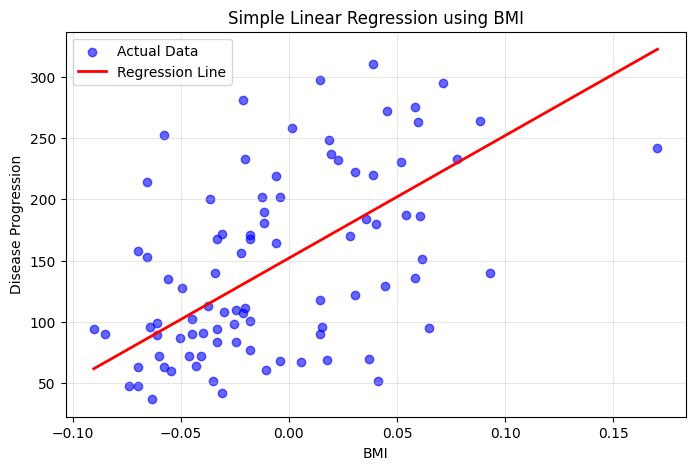

In [10]:

# Plot actual data points and regression line
plt.figure(figsize=(8, 5))

plt.scatter(
    X_test_simple["bmi"],
    y_test_simple,
    color="blue",
    alpha=0.6,
    label="Actual Data"
)

# Sort BMI values to draw a proper line
X_sorted = X_test_simple.sort_values("bmi")

plt.plot(
    X_sorted["bmi"],
    simple_model.predict(X_sorted),
    color="red",
    linewidth=2,
    label="Regression Line"
)

plt.xlabel("BMI")
plt.ylabel("Disease Progression")
plt.title("Simple Linear Regression using BMI")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [12]:

# Select all 10 input features
X_multi = X

print("All features selected successfully!")
print("Number of features:", X_multi.shape[1])

print("\nFeature names:")
print(X_multi.columns.tolist())


All features selected successfully!
Number of features: 10

Feature names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


In [13]:

# Split all 10 features into training and testing data
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train_multi))
print("Testing samples:", len(X_test_multi))


Training samples: 353
Testing samples: 89


In [17]:

# Create the Multiple Linear Regression model
multiple_model = LinearRegression()

# Train the model using all 10 features
multiple_model.fit(X_train_multi, y_train_multi)

print("Multiple Linear Regression model trained successfully!")
print("Intercept:", round(multiple_model.intercept_, 4))

print("\nCoefficients for each feature:")
for feature, coefficient in zip(X_multi.columns, multiple_model.coef_):
    print(f"{feature}: {coefficient:.4f}")


Multiple Linear Regression model trained successfully!
Intercept: 151.3456

Coefficients for each feature:
age: 37.9040
sex: -241.9644
bmi: 542.4288
bp: 347.7038
s1: -931.4888
s2: 518.0623
s3: 163.4200
s4: 275.3179
s5: 736.1989
s6: 48.6707


In [18]:

y_pred_multi = multiple_model.predict(X_test_multi)

print("First 10 actual values:")
print(y_test_multi.iloc[:10].to_numpy())

print("\nFirst 10 predicted values:")
print(np.round(y_pred_multi[:10], 2))


First 10 actual values:
[219.  70. 202. 230. 111.  84. 242. 272.  94.  96.]

First 10 predicted values:
[139.55 179.52 134.04 291.42 123.79  92.17 258.23 181.34  90.22 108.63]


In [19]:

mse_multi = mean_squared_error(y_test_multi, y_pred_multi)
r2_multi = r2_score(y_test_multi, y_pred_multi)

print("Multiple Linear Regression Evaluation")
print("-------------------------------------")
print("Mean Squared Error (MSE):", round(mse_multi, 4))
print("R² Score:", round(r2_multi, 4))


Multiple Linear Regression Evaluation
-------------------------------------
Mean Squared Error (MSE): 2900.1936
R² Score: 0.4526


In [20]:

comparison = pd.DataFrame({
    "Model": [
        "Simple Linear Regression (BMI)",
        "Multiple Linear Regression (All Features)"
    ],
    "MSE": [mse_simple, mse_multi],
    "R2 Score": [r2_simple, r2_multi]
})

display(comparison.round(4))


,Model,MSE,R2 Score
0,Simple Linear Regression (BMI),4061.8259,0.2334
1,Multiple Linear Regression (All Features),2900.1936,0.4526


## Comparison and Interpretation of Results

Two regression models were developed to predict diabetes disease progression using the Diabetes dataset.

**1. Simple Linear Regression:** This model used only BMI as the input feature. It obtained an MSE of 4061.8259 and an R² score of 0.2334. This indicates that BMI alone explains approximately 23.34% of the variation in the target variable.

**2. Multiple Linear Regression:** This model used all 10 input features. It obtained an MSE of 2900.1936 and an R² score of 0.4526. This indicates that the model explains approximately 45.26% of the variation in the target variable.

**Conclusion:** Multiple Linear Regression performed better on the test set because it achieved a lower MSE and a higher R² score than Simple Linear Regression. Using multiple features provides more information for predicting disease progression than using BMI alone. However, the R² score indicates that a substantial amount of variation remains unexplained.